# 3. What do the sales show?

Asks one question at a time of the cleaned data and answers it with money, not counts. The calculations are in `market_sales/analysis.py` and the charts in `market_sales/charts.py`, so this notebook is just the questions and the answers.

**This is sample data**, so the patterns show how to analyse sales and aren't facts about real customers.

**How to read the numbers:** *sales* means the price before the 5% tax, because tax belongs to the government, not the shop. The data doesn't say which currency the prices use. This notebook only describes the differences; whether any of them is bigger than chance is tested in notebook 4.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd

from market_sales import charts
from market_sales.analysis import average_daily_sales, gap, headline, sales_mix, sales_summary
from market_sales.cleaning import load_clean
from market_sales.config import RAW_DATA

pd.set_option("display.width", 140)
pd.set_option("display.float_format", "{:,.2f}".format)

df = load_clean(RAW_DATA)
top = headline(df)

## The big picture

In [2]:
print(f"{top['orders']:,} sales over {top['days']} days ({top['first_day']:%d %b} to {top['last_day']:%d %b %Y})")
print(f"Total sales: {top['sales']:,.0f}, or {top['average_daily_sales']:,.0f} per day on average")
print(f"A typical sale is {top['median_order']:,.0f} (the median). The average is higher, {top['average_order']:,.0f}, because a few large sales pull it up.")
print(f"Average rating: {top['average_rating']:.2f} out of 10")

1,000 sales over 89 days (01 Jan to 30 Mar 2019)
Total sales: 307,587, or 3,456 per day on average
A typical sale is 242 (the median). The average is higher, 308, because a few large sales pull it up.
Average rating: 6.97 out of 10


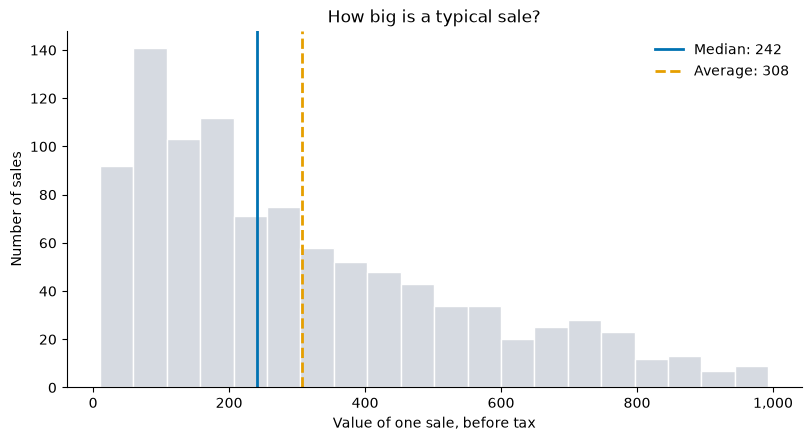

In [3]:
charts.order_size(df)

Most sales are small, and a smaller number are large. When that happens the median describes a typical sale better than the average.

## 1. Which city sells the most?

In [4]:
cities = sales_summary(df, 'city')
cities

,sales,orders,units,average_order,average_rating,share
city,,,,,,
Naypyitaw,"105,303.53",328,1831,321.05,7.07,0.34
Yangon,"101,143.21",340,1859,297.48,7.03,0.33
Mandalay,"101,140.64",332,1820,304.64,6.82,0.33


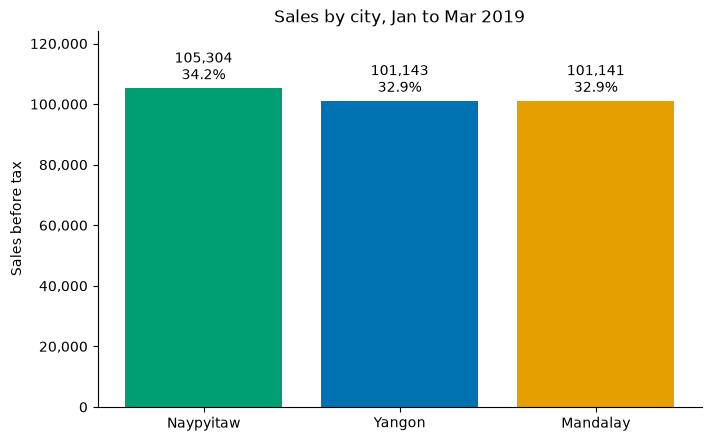

In [5]:
charts.city_sales(df)

In [6]:
best, worst = cities.index[0], cities.index[-1]
print(f"{best} sold the most and {worst} the least, but the gap is only {gap(cities['sales']):.1%}.")
print(f"Each city made between {cities['orders'].min()} and {cities['orders'].max()} sales, so they are about the same size.")

Naypyitaw sold the most and Mandalay the least, but the gap is only 4.1%.
Each city made between 328 and 340 sales, so they are about the same size.


The bars start at zero, so the picture is honest: the three cities are close.

## 2. What sells where?

In [7]:
products = sales_summary(df, 'product_line')
products[['sales', 'share', 'orders', 'average_order']]

,sales,share,orders,average_order
product_line,,,,
Food and beverages,"53,471.28",0.17,174,307.31
Sports and travel,"52,497.93",0.17,166,316.25
Electronic accessories,"51,750.03",0.17,170,304.41
Fashion accessories,"51,719.90",0.17,178,290.56
Home and lifestyle,"51,297.06",0.17,160,320.61
Health and beauty,"46,851.18",0.15,152,308.23


In [8]:
print(f"{products.index[0]} is the top line with {products['share'].iloc[0]:.1%} of sales, and {products.index[-1]} the lowest with {products['share'].iloc[-1]:.1%}.")
print(f"The biggest line is {gap(products['sales']):.1%} larger than the smallest.")

Food and beverages is the top line with 17.4% of sales, and Health and beauty the lowest with 15.2%.
The biggest line is 14.1% larger than the smallest.


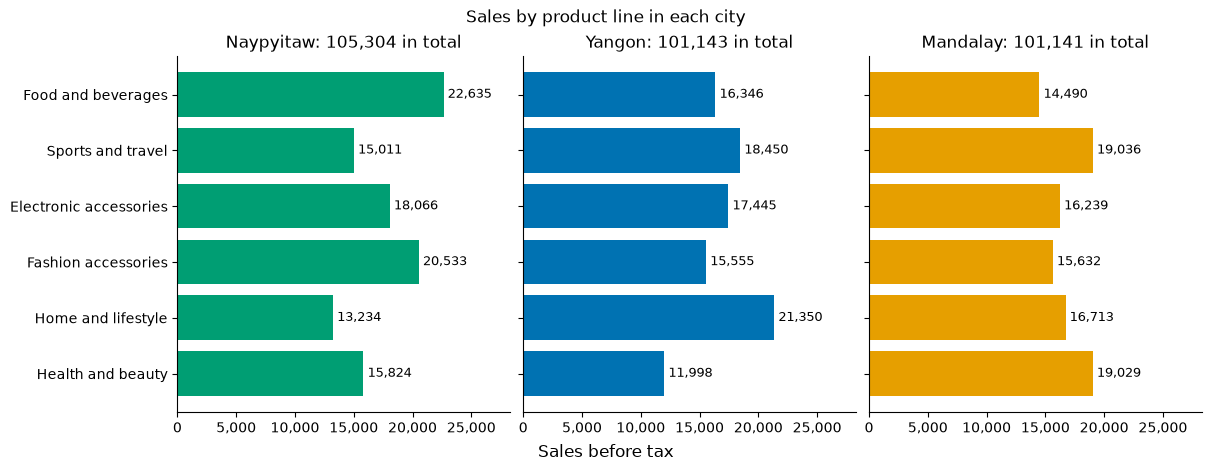

In [9]:
charts.product_by_city(df)

In [10]:
by_city = df.groupby(["city", "product_line"], observed=True)["subtotal"].sum().unstack()
leaders = by_city.idxmax(axis=1)
laggards = by_city.idxmin(axis=1)
for city in cities.index:
    print(f"{city}: strongest on {leaders[city]}, weakest on {laggards[city]}")

Naypyitaw: strongest on Food and beverages, weakest on Home and lifestyle
Yangon: strongest on Home and lifestyle, weakest on Health and beauty
Mandalay: strongest on Sports and travel, weakest on Food and beverages


Each city's strongest product line is different. The old notebook drew this as three pie charts, which are hard to compare. Here the products are in the same order in every panel, and the bars show money.

## 3. When do people shop?

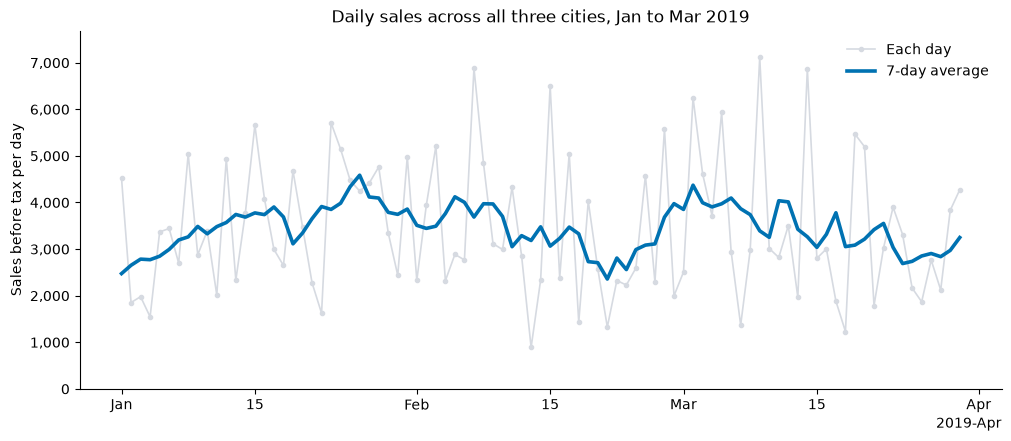

In [11]:
charts.daily_trend(df)

Daily sales jump around a lot, which is normal for a shop: the pale line is each day, and the thick line averages each week to show the trend.

### By day of the week

The chart uses average sales *per day*, because a weekday that appears 13 times in the period would otherwise beat one that appears 12 times.

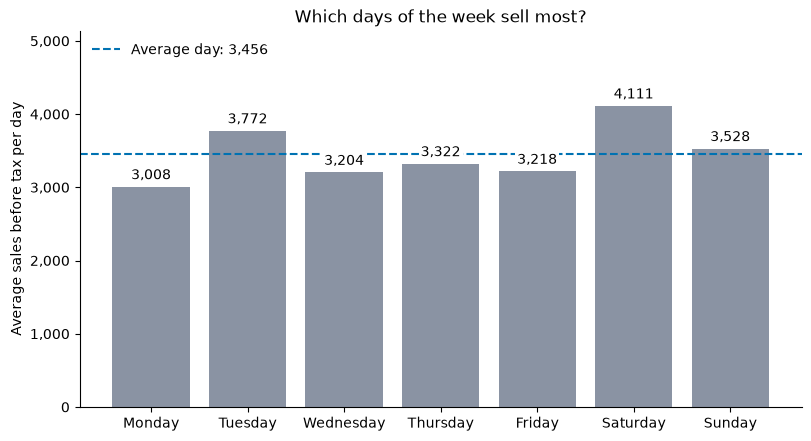

In [12]:
charts.weekday_pattern(df)

In [13]:
weekday = average_daily_sales(df, "weekday")
print(f"Best day: {weekday.idxmax()} ({weekday.max():,.0f} a day). Weakest: {weekday.idxmin()} ({weekday.min():,.0f}).")
print(f"The best day averages {gap(weekday):.0%} more than the weakest.")
weekend = df[df['is_weekend']]['subtotal'].sum() / df[df['is_weekend']]['date'].nunique()
weekdays_only = df[~df['is_weekend']]['subtotal'].sum() / df[~df['is_weekend']]['date'].nunique()
print(f"A weekend day averages {weekend:,.0f}; a weekday {weekdays_only:,.0f}.")

Best day: Saturday (4,111 a day). Weakest: Monday (3,008).
The best day averages 37% more than the weakest.
A weekend day averages 3,832; a weekday 3,309.


### By hour of the day

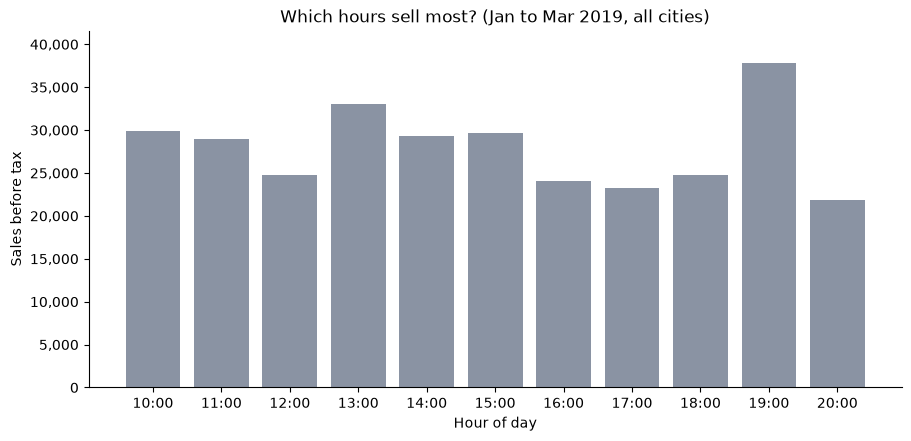

In [14]:
charts.hourly_pattern(df)

In [15]:
hourly = sales_summary(df, "hour", sort=False)["sales"]
print(f"Busiest hour: {hourly.idxmax()}:00 with {hourly.max() / hourly.sum():.1%} of all sales. Quietest: {hourly.idxmin()}:00 with {hourly.min() / hourly.sum():.1%}.")

Busiest hour: 19:00 with 12.3% of all sales. Quietest: 20:00 with 7.1%.

### By month

January has 31 days, February 28 and March 30, so the chart compares average sales *per day* and doesn't let February look weak just for being short.

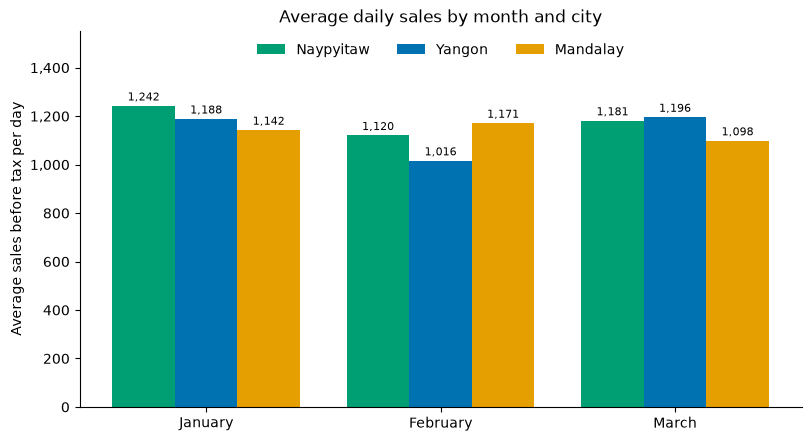

In [16]:
charts.monthly_by_city(df)

## 4. Who shops, and how do they pay?

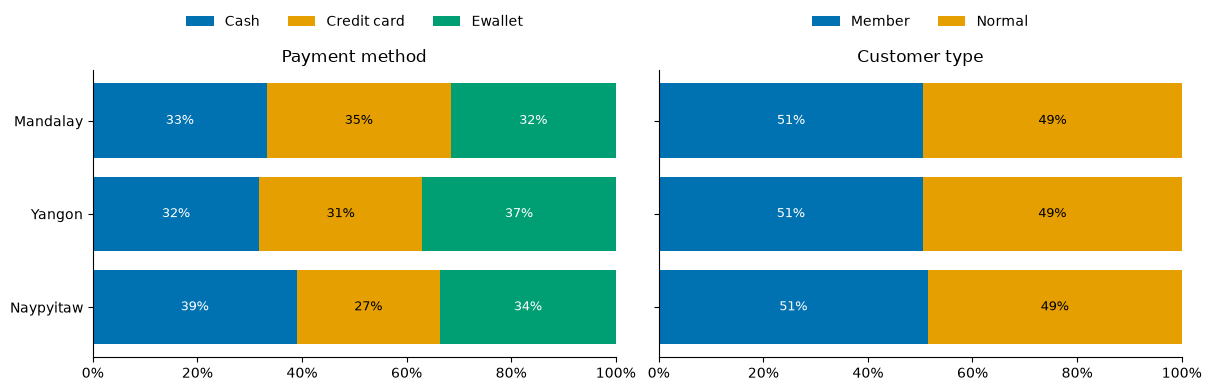

In [17]:
charts.payment_and_customer_mix(df)

In [18]:
print("Share of each city's sales by payment method:")
display(sales_mix(df, "city", "payment").map("{:.1%}".format))
print("Share of each city's sales by customer type:")
display(sales_mix(df, "city", "customer_type").map("{:.1%}".format))

Share of each city's sales by payment method:


payment,Cash,Credit card,Ewallet
city,,,
Mandalay,33.3%,35.2%,31.6%
Naypyitaw,39.0%,27.4%,33.6%
Yangon,31.8%,31.2%,37.0%


Share of each city's sales by customer type:


customer_type,Member,Normal
city,,
Mandalay,50.6%,49.4%
Naypyitaw,51.4%,48.6%
Yangon,50.5%,49.5%


In [19]:
print("By gender:")
display(sales_summary(df, "gender")[["sales", "share", "orders", "average_order"]])
print("By customer type:")
display(sales_summary(df, "customer_type")[["sales", "share", "orders", "average_order"]])

By gender:


,sales,share,orders,average_order
gender,,,,
Female,"159,888.50",0.52,501,319.14
Male,"147,698.88",0.48,499,295.99


By customer type:


,sales,share,orders,average_order
customer_type,,,,
Member,"156,403.28",0.51,501,312.18
Normal,"151,184.10",0.49,499,302.97


Payment methods are close to evenly split everywhere, and members and normal customers account for about half of sales each. Women's average sale is a little higher than men's, but Phase 4 will check whether that's more than chance.

## Summary

What stands out, from the numbers above:

In [20]:
cities = sales_summary(df, "city")
products = sales_summary(df, "product_line")
weekday = average_daily_sales(df, "weekday")
hourly = sales_summary(df, "hour", sort=False)["sales"]
rows = [
    ("City", f"{cities.index[0]} leads, {gap(cities['sales']):.1%} ahead of {cities.index[-1]}"),
    ("Product line", f"{products.index[0]} leads, {gap(products['sales']):.1%} ahead of {products.index[-1]}"),
    ("Day of week", f"{weekday.idxmax()} is highest, {gap(weekday):.0%} above {weekday.idxmin()}"),
    ("Hour", f"{hourly.idxmax()}:00 is the busiest, with {hourly.max() / hourly.sum():.1%} of all sales"),
]
pd.DataFrame(rows, columns=["Question", "What the numbers show"]).set_index("Question")

,What the numbers show
Question,
City,"Naypyitaw leads, 4.1% ahead of Mandalay"
Product line,"Food and beverages leads, 14.1% ahead of Healt..."
Day of week,"Saturday is highest, 37% above Monday"
Hour,"19:00 is the busiest, with 12.3% of all sales"


The largest differences are between days of the week and between hours of the day, while cities and customer types look similar. But a difference is only interesting if it's bigger than chance would produce, and with 1,000 sales over 89 days that's not obvious. **Notebook 4** tests each of these properly.